# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 11: Comparativo Multimodelo com o Extrator HHT (Random Forest, MLP, SVM e CNN)

Neste notebook, investigamos o comportamento da **Transformada de Hilbert-Huang (HHT Pura)** ($256\text{ bins}$ de frequência instantânea, de $1{,}0\text{ Hz}$ a $1000\text{ Hz}$) através de **quatro famílias distintas de aprendizado de máquina**:

1. **Random Forest (100 árvores de decisão):** sem limite de profundidade, com balanceamento de pesos de classe.
2. **Multi-Layer Perceptron (MLP PyTorch `[32, 16]`):** rede feedforward com `BatchNorm1d` e `Dropout 0.2`, 30 épocas sem early stopping e sem semente fixa.
3. **SVM Nyström Gaussiano ($m=6000$):** núcleo RBF aproximado com penalidade ElasticNet (`max_iter=200`, early stopping).
4. **CNN 2D PyTorch `[64, 32]`:** convoluções 2D em imagens de $32 \times 256$ (32 janelas HHT consecutivas). **Este modelo colapsou** (ver Seção 2).

Todos os modelos foram avaliados por `scratch/eval_hht_models_5x2cv.py` nos **10 folds oficiais do $5\times2$cv** com **particionamento estratificado por gravação de áudio (`ID`)** sobre os **1.706 áudios de UO** do IARA (o mesmo protocolo do artigo de *Silva et al.*, IEEE Access 2025; o isolamento é por gravação, não por navio), com voto majoritário por arquivo.

> **Limitação da feature:** o `cache_hht.pkl` usa janelas de 2,56 s com passo de 5,12 s; **metade de cada gravação não é analisada**.

Todas as tabelas e figuras são calculadas na execução por `notebooks/iara_results.py` a partir das predições por janela em `results/trainings/{multirep,tests}/<exp>/eval/fold_k/`. **ACC = acurácia balanceada** (média dos recalls), como a coluna ACC da Tabela 7 do artigo.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display, HTML
except ImportError:
    display = print
for _p in ('.', 'notebooks'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R  # módulo único de métricas (lê os CSVs por janela em results/trainings)

# Configuração de estilo visual acadêmico premium
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.dpi': 120
})

HHT = {'Random Forest (100 árvores)': ('rf_hht_n100_balanced_4c', 'rf_hht_n100_balanced_3c'), 'MLP PyTorch [32, 16]': ('mlp_hht_h32-16_e30_noseed_4c', 'mlp_hht_h32-16_e30_noseed_3c'), 'SVM Nyström (m=6000)': ('svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c', 'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_3c'), 'CNN 2D PyTorch [64, 32] (COLAPSADA)': ('cnn2d_hht_w32_b32_e25_4c', 'cnn2d_hht_w32_b32_e25_3c')}
EXP_SVM_LOFAR, EXP_SVM_MEL, EXP_MLP_LOFAR = ('svm_nystroem_6000_lofar_elasticnet_l1r0.15', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', 'mlp_lofar')
EXP_RF_LOFAR, EXP_RF_MEL = ('rf_lofar5s_n100_balanced_4c', 'rf_mel5s_n100_balanced_4c')
EXP_DEMON = ('mlp_demon_h32-16_e35_4c', 'mlp_demon_h32-16_e35_3c')
EXP_BIGRU_HHT = ('bigru_att_hht_h64_s15-5_e20_4c', 'bigru_att_hht_h64_s15-5_e20_3c')
NB10_SVMS = {'MEL': 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', 'LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15', 'HHT': 'svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c', 'DEMON': 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c'}

import numpy as np
import pandas as pd

def matriz_confusao(exp, classes):
    """Matriz de confusão por arquivo somada nos 10 folds, normalizada por linha (%)."""
    df = pd.concat(R.file_predictions(exp).values(), ignore_index=True)
    cm = pd.crosstab(df.Target, df.Prediction).reindex(index=classes, columns=classes, fill_value=0)
    return cm.div(cm.sum(axis=1), axis=0).values * 100, int(cm.values.sum())

def exclusivos_small(exps):
    """Instâncias arquivo x fold de SMALL acertadas por UM único modelo do conjunto."""
    out = {k: 0 for k in exps}
    total = 0
    for k, df in R.aligned(list(exps.values())).items():
        d = df[df.Target == 0]
        total += len(d)
        hit = np.column_stack([d[e].values == 0 for e in exps.values()])
        so_um = hit.sum(axis=1) == 1
        for i, nome in enumerate(exps):
            out[nome] += int((so_um & hit[:, i]).sum())
    return out, total

print('Ambiente configurado com sucesso! Bibliotecas prontas.')


Ambiente configurado com sucesso! Bibliotecas prontas.


## 1. Tabela Mestra Consolidada: HHT vs. DEMON vs. LOFAR/MEL (local e artigo)

* Linhas **"(Silva et al., 2025)"**: valores da Tabela 7 do artigo (4 classes; o artigo não traz recalls nem 3 classes).
* Linhas **"(local)"**: re-execuções locais lidas dos CSVs. `RF LOFAR/MEL (local)` usam caches de **5,12 s** (`lofar5s`/`mel5s`), resolução temporal 10× menor que a do artigo.
* Colunas **3C**: para os modelos HHT/DEMON/BiGRU, modelo **retreinado** sem BACKGROUND (`*_3c`); para os SVMs LOFAR/MEL, o modelo de 4 classes avaliado só nos navios, contando predição BACKGROUND como erro (`4c_sem_bg`). Os dois tipos **não** são diretamente comparáveis (coluna `Tipo 3C`).


In [2]:
def linha(modelo, rep, exp4=None, exp3=None, modo3='3c', artigo=None):
    d = {'Modelo': modelo, 'Rep': rep}
    if artigo is not None:
        a = R.ARTICLE_TABLE7[artigo]
        d.update({'Acc 4C (%)': a['ACC'][0], 'SP 4C (%)': a['SP'][0], 'SP 4C std': a['SP'][1]})
    if exp4 is not None:
        s = R.summary(exp4, '4c')
        d.update({'Acc 4C (%)': s['ACC'][0], 'SP 4C (%)': s['SP'][0], 'SP 4C std': s['SP'][1],
                  'Rec SMALL (%)': s['R_SMALL'][0], 'Rec MED (%)': s['R_MEDIUM'][0],
                  'Rec LARGE (%)': s['R_LARGE'][0], 'Rec AMB (%)': s['R_BACKGROUND'][0]})
    if exp3 is not None:
        s3 = R.summary(exp3, modo3)
        d.update({'Acc 3C (%)': s3['ACC'][0], 'SP 3C (%)': s3['SP'][0],
                  'Tipo 3C': 'retreinado' if modo3 == '3c' else '4C sem BG'})
    d['Fonte'] = 'Tabela 7 do artigo' if artigo is not None else (exp4 or exp3)
    return d

tabela = [
    linha('MLP (Silva et al., 2025)', 'LOFAR', artigo=('MLP', 'LOFAR')),
    linha('CNN (Silva et al., 2025)', 'LOFAR', artigo=('CNN', 'LOFAR')),
    linha('RF (Silva et al., 2025)', 'LOFAR', artigo=('RF', 'LOFAR')),
    linha('CNN (Silva et al., 2025)', 'MEL', artigo=('CNN', 'MEL')),
    linha('MLP (Silva et al., 2025)', 'MEL', artigo=('MLP', 'MEL')),
    linha('RF (Silva et al., 2025)', 'MEL', artigo=('RF', 'MEL')),
    linha('MLP (local)', 'LOFAR', EXP_MLP_LOFAR),
    linha('SVM m=6000 (local)', 'LOFAR', EXP_SVM_LOFAR, EXP_SVM_LOFAR, '4c_sem_bg'),
    linha('SVM m=4000 (local)', 'MEL', EXP_SVM_MEL, EXP_SVM_MEL, '4c_sem_bg'),
    linha('RF 100t (local, cache 5,12 s)', 'LOFAR', EXP_RF_LOFAR),
    linha('RF 100t (local, cache 5,12 s)', 'MEL', EXP_RF_MEL),
] + [linha(rot, 'HHT', e4, e3) for rot, (e4, e3) in HHT.items()] + [
    linha('BiGRU + atenção (local)', 'HHT', *EXP_BIGRU_HHT),
    linha('MLP [32, 16], 35 épocas (local)', 'DEMON', *EXP_DEMON),
]
df_master = pd.DataFrame(tabela).set_index('Modelo').round(2)
display(df_master)


,Rep,Acc 4C (%),SP 4C (%),SP 4C std,Fonte,Rec SMALL (%),Rec MED (%),Rec LARGE (%),Rec AMB (%),Acc 3C (%),SP 3C (%),Tipo 3C
Modelo,,,,,,,,,,,,
"MLP (Silva et al., 2025)",LOFAR,67.48,66.51,1.39,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"CNN (Silva et al., 2025)",LOFAR,67.02,66.05,1.90,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"RF (Silva et al., 2025)",LOFAR,58.87,56.92,1.69,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"CNN (Silva et al., 2025)",MEL,64.99,63.52,2.26,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"MLP (Silva et al., 2025)",MEL,64.51,63.38,1.81,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"RF (Silva et al., 2025)",MEL,62.64,62.22,1.86,Tabela 7 do artigo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MLP (local),LOFAR,67.22,66.24,1.78,mlp_lofar,46.35,61.48,74.72,86.33,NaN,NaN,NaN
SVM m=6000 (local),LOFAR,65.47,63.83,1.91,svm_nystroem_6000_lofar_elasticnet_l1r0.15,38.15,60.40,76.31,87.04,58.29,56.96,4C sem BG
SVM m=4000 (local),MEL,64.56,63.78,1.14,svm_nystroem_4000_log_melgram_elasticnet_l1r0....,50.73,60.40,69.25,77.86,60.13,59.46,4C sem BG


## 2. Comparativo Global: O Desempenho da HHT Pura (4 Classes vs. 3 Classes)

No gráfico abaixo, comparamos a **Acurácia Balanceada** e o **Índice SP** de cada uma das 4 arquiteturas no problema de 4 classes e no de 3 classes (modelos retreinados só com embarcações), com linhas de referência:


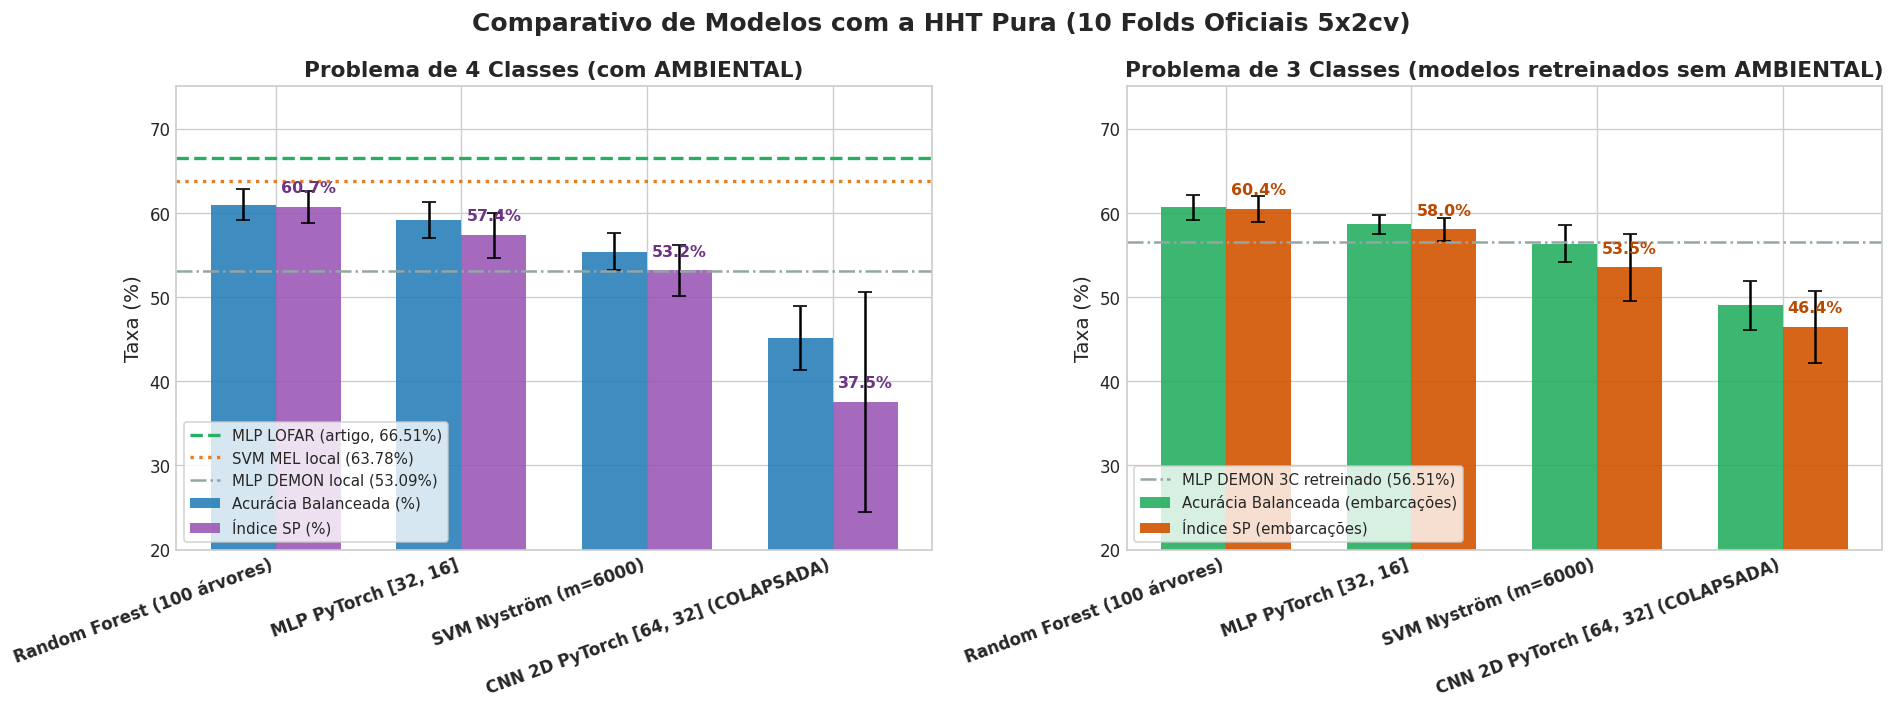

F-test 5x2cv (SP):
  rf_hht_n100_balanced_4c vs mlp_hht_h32-16_e30_noseed_4c: F = 2.77, p = 0.136
  rf_hht_n100_balanced_3c vs mlp_hht_h32-16_e30_noseed_3c: F = 3.46, p = 0.091
  rf_hht_n100_balanced_4c vs rf_lofar5s_n100_balanced_4c: F = 6.23, p = 0.028
  rf_hht_n100_balanced_4c vs rf_mel5s_n100_balanced_4c: F = 0.88, p = 0.596
  rf_hht_n100_balanced_4c vs mlp_demon_h32-16_e35_4c: F = 12.06, p = 0.007
  rf_hht_n100_balanced_3c vs mlp_demon_h32-16_e35_3c: F = 5.03, p = 0.044
CNN 2D 4C — SP por fold: [41.0, 37.2, 42.2, 50.5, 36.3, 43.1, 0.0, 42.7, 42.7, 39.5]


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

hht_models = list(HHT)
s4 = [R.summary(e4, '4c') for e4, _ in HHT.values()]
s3 = [R.summary(e3, '3c') for _, e3 in HHT.values()]
x = np.arange(len(hht_models))
w = 0.35
art = R.ARTICLE_TABLE7[('MLP', 'LOFAR')]['SP'][0]
mel = R.summary(EXP_SVM_MEL)['SP'][0]
dem4 = R.summary(EXP_DEMON[0])['SP'][0]
dem3 = R.summary(EXP_DEMON[1], '3c')['SP'][0]

# Gráfico 1: 4 Classes
ax1.bar(x - w/2, [s['ACC'][0] for s in s4], w, yerr=[s['ACC'][1] for s in s4], capsize=4, label='Acurácia Balanceada (%)', color='#2980b9', alpha=0.9)
rects2 = ax1.bar(x + w/2, [s['SP'][0] for s in s4], w, yerr=[s['SP'][1] for s in s4], capsize=4, label='Índice SP (%)', color='#9b59b6', alpha=0.9)
ax1.axhline(art, color='#27ae60', linestyle='--', lw=2, label=f'MLP LOFAR (artigo, {art:.2f}%)')
ax1.axhline(mel, color='#e67e22', linestyle=':', lw=2, label=f'SVM MEL local ({mel:.2f}%)')
ax1.axhline(dem4, color='#95a5a6', linestyle='-.', lw=1.5, label=f'MLP DEMON local ({dem4:.2f}%)')
ax1.set_title('Problema de 4 Classes (com AMBIENTAL)', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(hht_models, rotation=20, ha='right', fontweight='bold')
ax1.set_ylabel('Taxa (%)')
ax1.set_ylim(20, 75)
ax1.legend(loc='lower left', frameon=True, fontsize=9)
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 7), textcoords='offset points',
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#6c3483')

# Gráfico 2: 3 Classes (retreinados)
ax2.bar(x - w/2, [s['ACC'][0] for s in s3], w, yerr=[s['ACC'][1] for s in s3], capsize=4, label='Acurácia Balanceada (embarcações)', color='#27ae60', alpha=0.9)
rects4 = ax2.bar(x + w/2, [s['SP'][0] for s in s3], w, yerr=[s['SP'][1] for s in s3], capsize=4, label='Índice SP (embarcações)', color='#d35400', alpha=0.9)
ax2.axhline(dem3, color='#95a5a6', linestyle='-.', lw=1.5, label=f'MLP DEMON 3C retreinado ({dem3:.2f}%)')
ax2.set_title('Problema de 3 Classes (modelos retreinados sem AMBIENTAL)', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(hht_models, rotation=20, ha='right', fontweight='bold')
ax2.set_ylabel('Taxa (%)')
ax2.set_ylim(20, 75)
ax2.legend(loc='lower left', frameon=True, fontsize=9)
for rect in rects4:
    h = rect.get_height()
    ax2.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 7), textcoords='offset points',
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#ba4a00')

plt.suptitle('Comparativo de Modelos com a HHT Pura (10 Folds Oficiais 5x2cv)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

print('F-test 5x2cv (SP):')
for a, b, m in [(HHT['Random Forest (100 árvores)'][0], HHT['MLP PyTorch [32, 16]'][0], '4c'),
                (HHT['Random Forest (100 árvores)'][1], HHT['MLP PyTorch [32, 16]'][1], '3c'),
                (HHT['Random Forest (100 árvores)'][0], EXP_RF_LOFAR, '4c'), (HHT['Random Forest (100 árvores)'][0], EXP_RF_MEL, '4c'),
                (HHT['Random Forest (100 árvores)'][0], EXP_DEMON[0], '4c'), (HHT['Random Forest (100 árvores)'][1], EXP_DEMON[1], '3c')]:
    F, p = R.f_test_5x2(a, b, mode_a=m, mode_b=m)
    print(f'  {a} vs {b}: F = {F:.2f}, p = {p:.3f}')
cnn = R.fold_metrics(HHT['CNN 2D PyTorch [64, 32] (COLAPSADA)'][0])
print('CNN 2D 4C — SP por fold:', cnn['SP'].round(1).tolist())


### Principais Observações do Comparativo Global:
*(Números calculados dos CSVs na geração; conferir com as saídas acima.)*

1. **4 classes:** o melhor modelo HHT é o Random Forest (100 árvores) (SP 60,70 ± 1,89), seguido do MLP PyTorch [32, 16] (SP 57,35 ± 2,67); são **equivalentes** (diferença não significativa) (F-test 5×2cv, p = 0,136).
2. **HHT não supera o LOFAR nem o MEL no mesmo classificador:** o RF com HHT (SP 60,70 ± 1,89) fica abaixo do RF LOFAR local (SP 63,07 ± 1,81; p = 0,028, significativo) e é equivalente ao RF MEL local (SP 61,50 ± 1,89; p = 0,596). A comparação anterior, contra o RF LOFAR da **Tabela 7 do artigo** (SP 56,92), misturava pipelines diferentes (features de 0,512 s e outros hiperparâmetros no artigo) e levava à conclusão oposta.
3. **HHT × DEMON:** o melhor HHT em 4 classes (Random Forest (100 árvores)) contra o MLP DEMON local (SP 53,09 ± 2,69): p = 0,007 (diferença significativa). A comparação por arquitetura está na Seção 5.2.
4. **3 classes (retreinados):** o melhor é o Random Forest (100 árvores) (SP 60,44 ± 1,54), seguido do MLP PyTorch [32, 16] (SP 58,01 ± 1,40; p = 0,091). O SVM LOFAR m=6000 avaliado sem BACKGROUND (modelo 4C, `4c_sem_bg`) dá SP 56,96 ± 1,98, mas não é um modelo retreinado e não serve de "teto" direto.
5. **CNN 2D colapsada:** SP 37,53 ± 13,05 em 4 classes, com SP por fold de 0,0 a 50,5 e recall de SMALL de 5,6 a 36,5% por fold. Com o passo de 5,12 s, uma imagem de 32 janelas cobre ~164 s e cada gravação gera só 1 ou 2 imagens (as curtas, completadas por *wrap padding*). O resultado reflete esse desenho de treino, não uma propriedade da HHT; o modelo não deve ser usado como baseline nem para concluir que "convoluções borram as raias".


## 3. Análise de Sensibilidade por Classe (Recalls)

Abaixo avaliamos o recall de cada modelo em cada classe do problema de 4 classes com HHT:


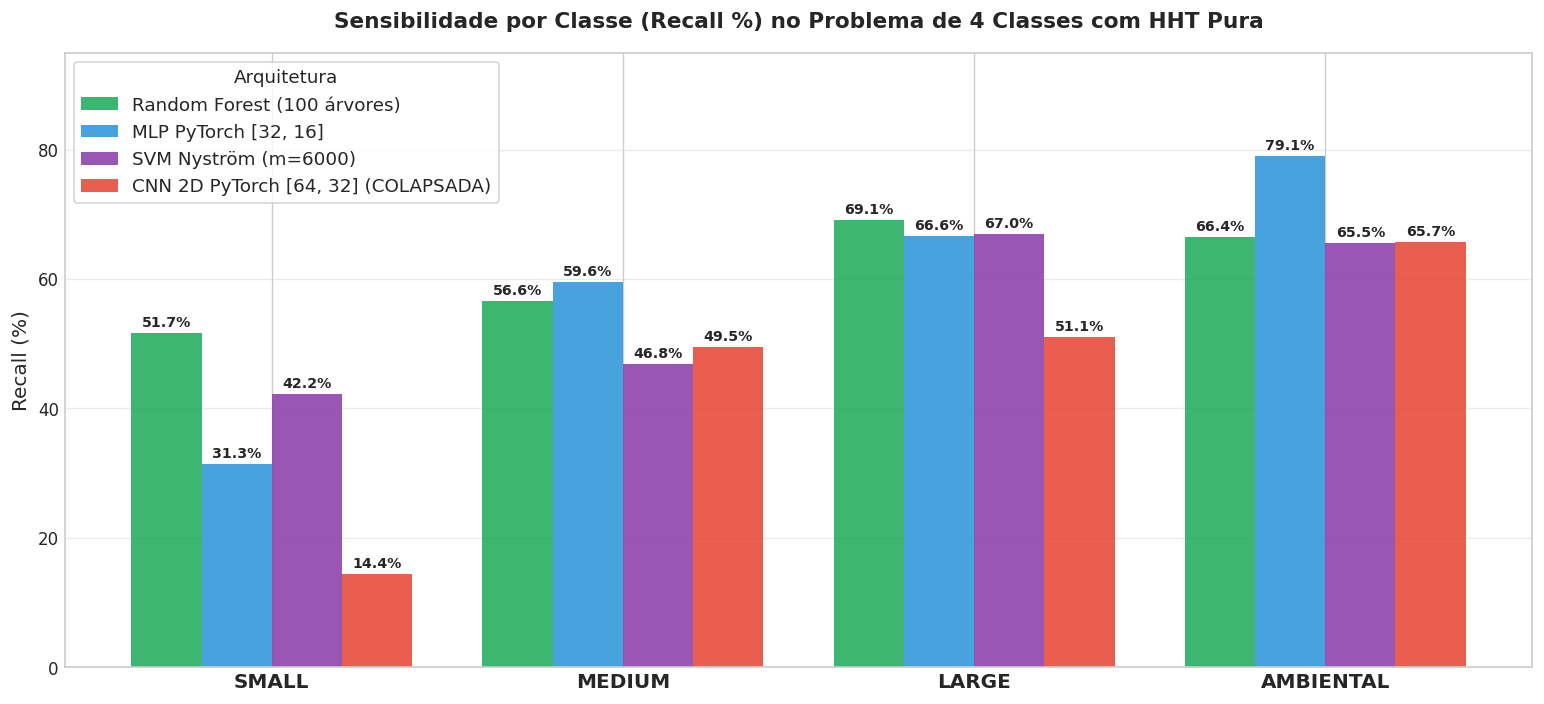

In [4]:
classes = ['SMALL', 'MEDIUM', 'LARGE', 'AMBIENTAL']
models_subset = list(HHT)
recalls_matrix = np.array([[R.summary(e4)['R_' + c][0] for c in R.CLASSES] for e4, _ in HHT.values()])

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(classes))
width = 0.20
colors = ['#27ae60', '#3498db', '#8e44ad', '#e74c3c']

for i, (m_name, color) in enumerate(zip(models_subset, colors)):
    offset = (i - 1.5) * width
    rects = ax.bar(x + offset, recalls_matrix[i], width, label=m_name, color=color, alpha=0.9)
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_title('Sensibilidade por Classe (Recall %) no Problema de 4 Classes com HHT Pura', fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=12, fontweight='bold')
ax.set_ylabel('Recall (%)', fontsize=12)
ax.set_ylim(0, 95)
ax.legend(title='Arquitetura', loc='upper left', frameon=True)
ax.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.show()


### Leitura da Sensibilidade por Classe:
1. **SMALL:** o maior recall é o do Random Forest (100 árvores) (51,69%), seguido do SVM Nyström (m=6000) (42,25%). A explicação de que as árvores "capturam transientes de alta frequência" é uma hipótese, não testada aqui.
2. **AMBIENTAL:** o maior recall é o do MLP PyTorch [32, 16] (79,08%). Atribuir isso à `BatchNorm1d` não é sustentado por nenhum experimento de ablação.
3. **LARGE:** nos três modelos que não colapsaram o recall vai de 66,64% a 69,11%. O máximo local em ~19 Hz visto no Notebook 9 vem de **uma** gravação LARGE e não basta para explicar o desempenho na classe.


## 4. Matrizes de Confusão Acumuladas nos 10 Folds ($5\times2$cv)

### 4.1 Problema de 4 Classes (SMALL, MEDIUM, LARGE, AMBIENTAL)
Matrizes por arquivo, somadas nos 10 folds (6390 avaliações de teste = instâncias arquivo × fold) e normalizadas por linha:


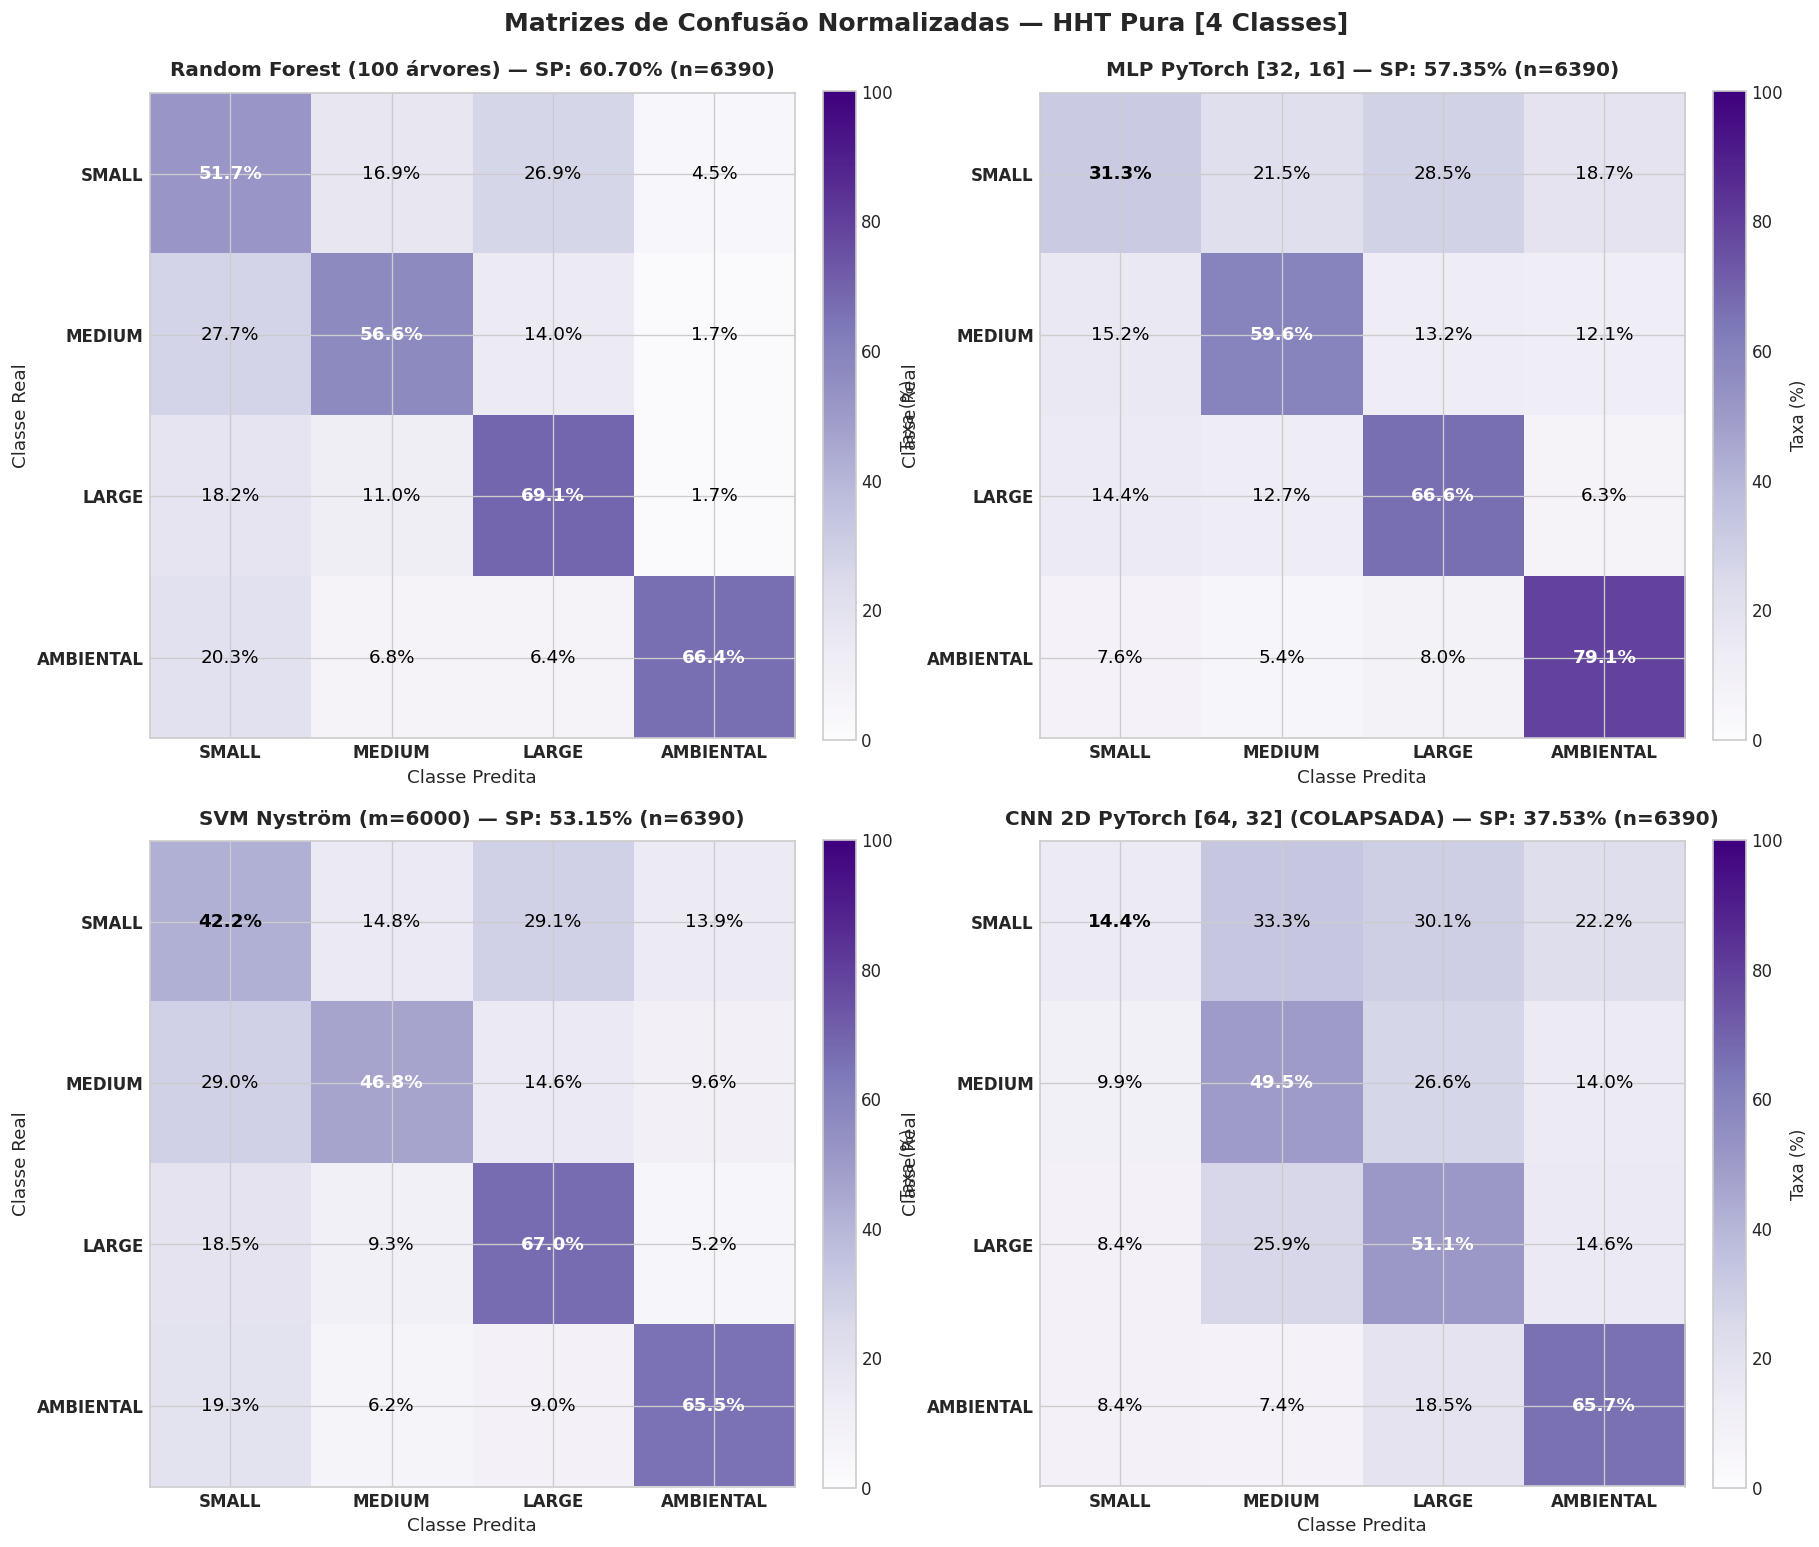

In [5]:
classes = ['SMALL', 'MEDIUM', 'LARGE', 'AMBIENTAL']
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, (rot, (e4, _)) in enumerate(HHT.items()):
    cm, n = matriz_confusao(e4, [0, 1, 2, 3])
    sp = R.summary(e4)['SP'][0]
    ax = axes[idx]
    im = ax.imshow(cm, cmap='Purples', vmin=0, vmax=100)
    ax.set_title(f'{rot} — SP: {sp:.2f}% (n={n})', fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels(classes, fontsize=10, fontweight='bold')
    ax.set_yticklabels(classes, fontsize=10, fontweight='bold')
    ax.set_xlabel('Classe Predita', fontsize=11)
    ax.set_ylabel('Classe Real', fontsize=11)
    for i in range(4):
        for j in range(4):
            val = cm[i, j]
            ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color='white' if val > 45 else 'black',
                    fontsize=11, fontweight='bold' if i == j else 'normal')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Taxa (%)', fontsize=10)

plt.suptitle('Matrizes de Confusão Normalizadas — HHT Pura [4 Classes]', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


### 4.2 Matrizes de Confusão no Problema de 3 Classes (modelos retreinados: SMALL, MEDIUM, LARGE)

Ao excluirmos a classe `AMBIENTAL` (e retreinarmos os modelos), avaliamos a capacidade do espectro de Hilbert-Huang de discriminar os portes de embarcação:


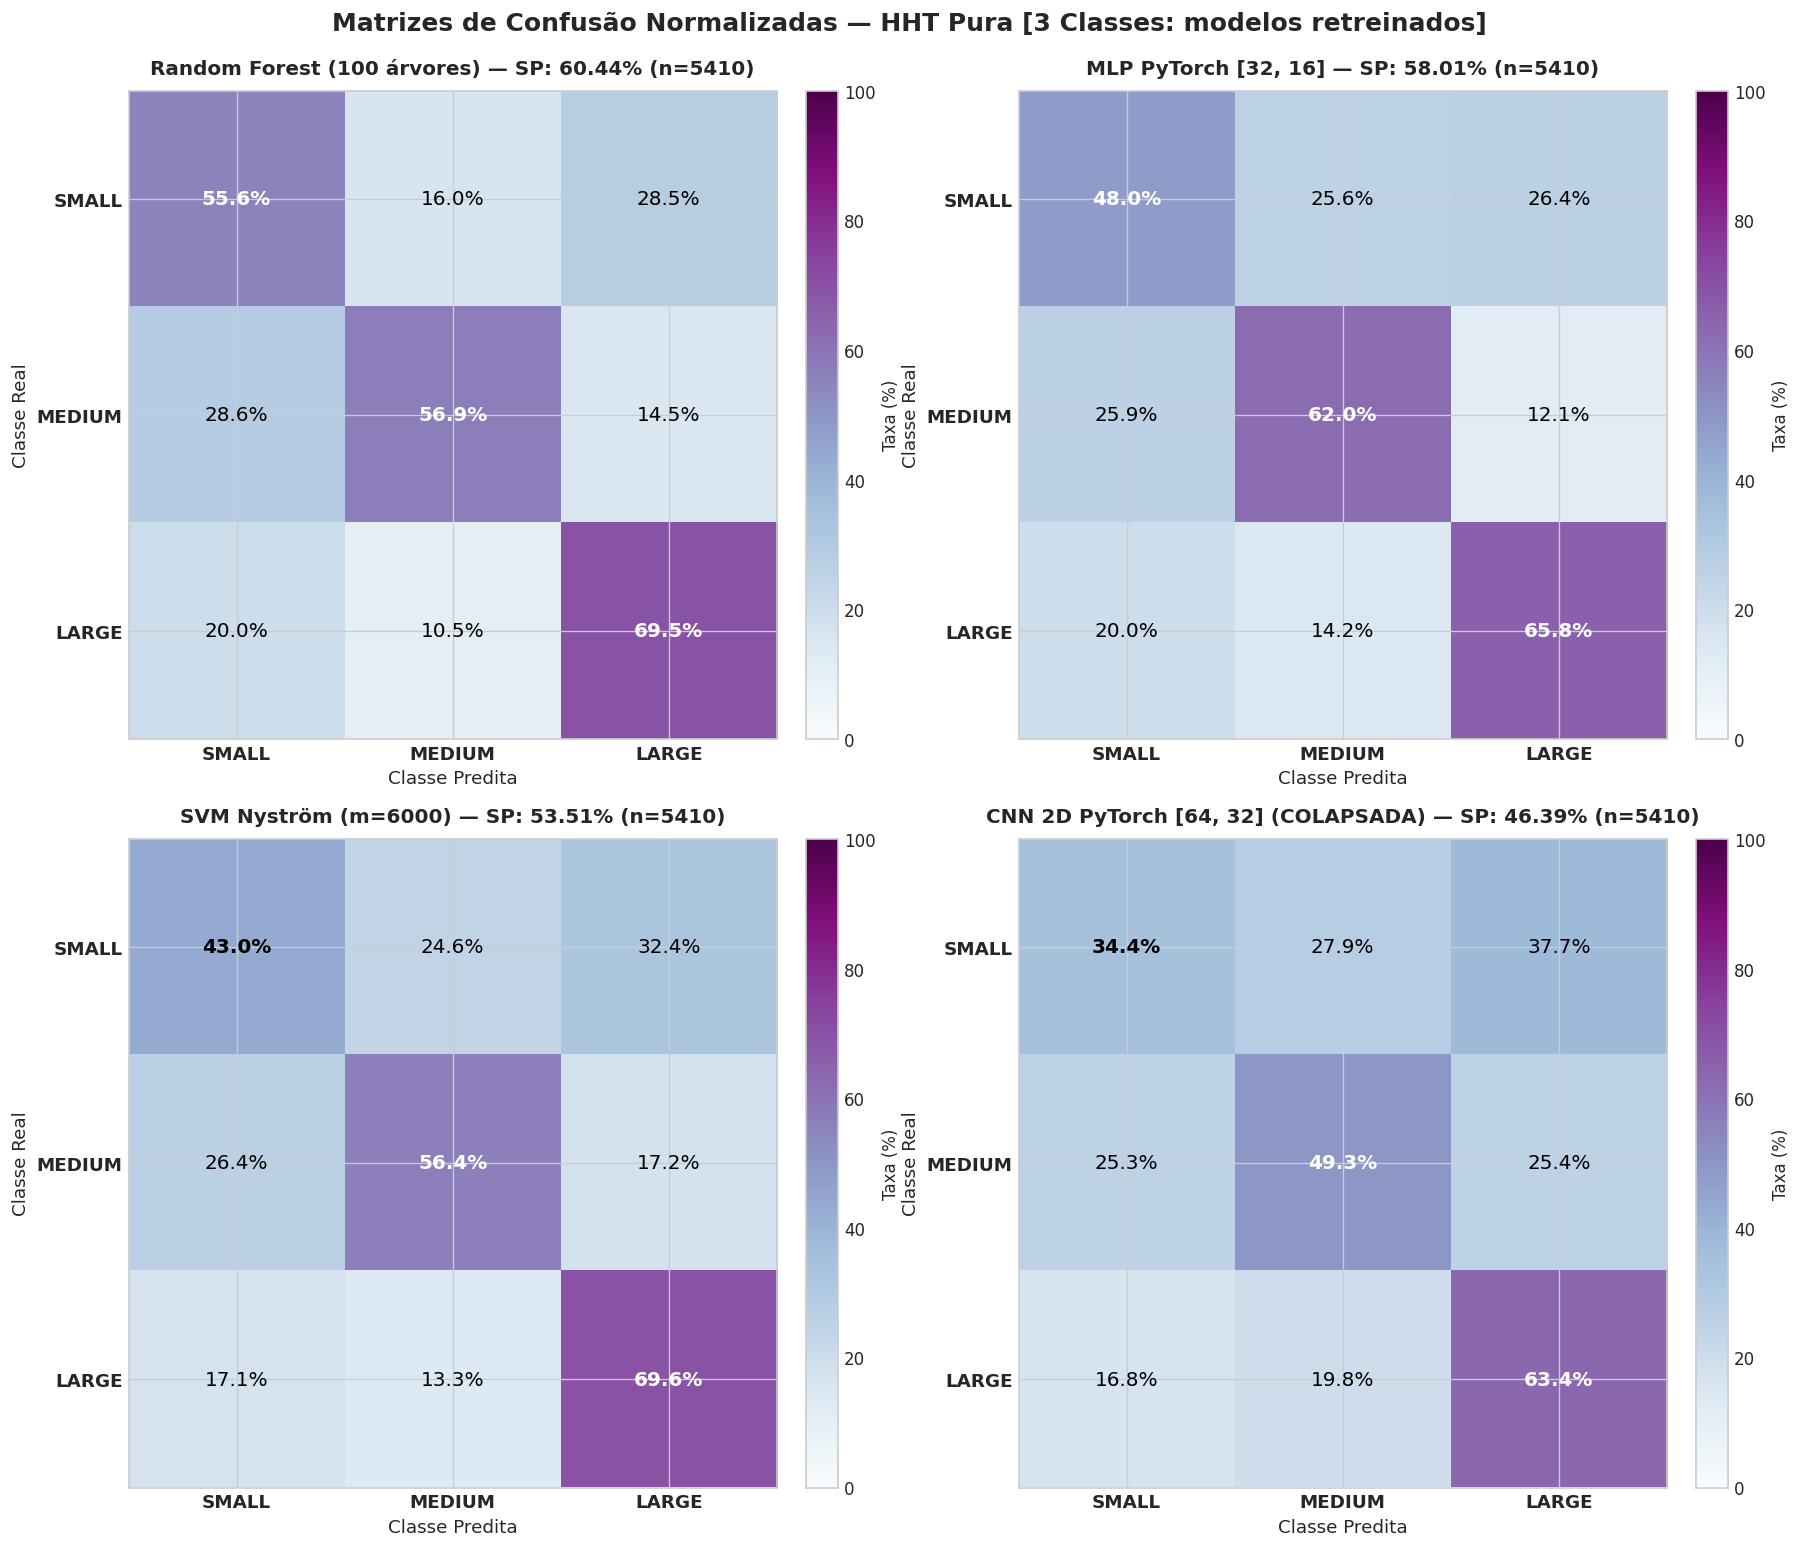

In [6]:
classes_3c = ['SMALL', 'MEDIUM', 'LARGE']
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, (rot, (_, e3)) in enumerate(HHT.items()):
    cm, n = matriz_confusao(e3, [0, 1, 2])
    sp = R.summary(e3, '3c')['SP'][0]
    ax = axes[idx]
    im = ax.imshow(cm, cmap='BuPu', vmin=0, vmax=100)
    ax.set_title(f'{rot} — SP: {sp:.2f}% (n={n})', fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(classes_3c, fontsize=11, fontweight='bold')
    ax.set_yticklabels(classes_3c, fontsize=11, fontweight='bold')
    ax.set_xlabel('Classe Predita', fontsize=11)
    ax.set_ylabel('Classe Real', fontsize=11)
    for i in range(3):
        for j in range(3):
            val = cm[i, j]
            ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color='white' if val > 45 else 'black',
                    fontsize=12, fontweight='bold' if i == j else 'normal')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Taxa (%)', fontsize=10)

plt.suptitle('Matrizes de Confusão Normalizadas — HHT Pura [3 Classes: modelos retreinados]', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


### Análise do Padrão de Erro em SMALL e o que ela permite concluir:
1. **Direção da confusão de SMALL no HHT (3 classes):** SMALL → LARGE em 28,5% das instâncias de SMALL no RF e 37,7% na CNN (colapsada); SMALL → MEDIUM em 16,0% no RF.
2. **SVM MEL (4 classes, o mesmo modelo do Notebook 10):** dos 877 erros em 1780 instâncias de SMALL, 432 (49,3%) foram para MEDIUM (24,27% de todas as instâncias de SMALL).
3. **Não é "complementaridade perfeita":** nas 432 instâncias em que o SVM MEL errou SMALL → MEDIUM, o RF HHT (4 classes) acertou 190 (44,0%) e errou **para a mesma classe** (MEDIUM) em 155 (35,9%).
4. **Oráculo do Notebook 10 (SVMs MEL, LOFAR, HHT e DEMON):** recall de SMALL do oráculo observado = 80,1%, **abaixo** do esperado se os erros fossem independentes (87,6% = $1-\prod_i(1-r_i)$). Ou seja, os erros são positivamente correlacionados. Além disso, um oráculo (acerta se *algum* modelo acerta) não é um sistema realizável: precisa saber a resposta para escolher o modelo.


In [7]:
# Conferência dos números da análise acima
print('Oráculo dos 4 SVMs do Notebook 10 (observado vs. esperado com erros independentes):')
display(R.oracle_recall(list(NB10_SVMS.values())).round(2))
excl, tot = exclusivos_small(NB10_SVMS)
print(f'Instâncias arquivo x fold de SMALL acertadas por um único SVM (de {tot}):', excl)
print('Recall SMALL de cada SVM:', {k: round(R.summary(v)['R_SMALL'][0], 2) for k, v in NB10_SVMS.items()})


Oráculo dos 4 SVMs do Notebook 10 (observado vs. esperado com erros independentes):


,oráculo observado,esperado c/ erros independentes
SMALL,80.11,87.62
MEDIUM,82.68,95.59
LARGE,90.33,98.94
BACKGROUND,95.51,99.54


Instâncias arquivo x fold de SMALL acertadas por um único SVM (de 1780): {'MEL': 175, 'LOFAR': 50, 'HHT': 176, 'DEMON': 100}
Recall SMALL de cada SVM: {'MEL': np.float64(50.73), 'LOFAR': np.float64(38.15), 'HHT': np.float64(42.81), 'DEMON': np.float64(28.43)}


## 5. Diagnóstico e Conclusões

### 5.1 O melhor modelo HHT: Random Forest (100 árvores) (SP 60,70 ± 1,89)
* É o melhor HHT em SP médio, mas a diferença para o segundo (MLP PyTorch [32, 16]) **não** é significativa (p = 0,136).
* As explicações mecânicas (resiliência a *mode mixing* por cortes ortogonais; invariância a transformações monotônicas) são **hipóteses plausíveis**, não testadas neste notebook.

### 5.2 O Confronto HHT vs. DEMON vs. LOFAR
**HHT × DEMON no mesmo classificador** (SP em 4 classes, F-test 5×2cv):

| Arquitetura | SP HHT | SP DEMON | Δ (p.p.) | p | Observação |
| :--- | :---: | :---: | :---: | :---: | :--- |
| Random Forest | 60,70 ± 1,89 | 44,44 ± 2,24 | 16,26 | 0,001 | mesma configuração |
| MLP [32, 16] | 55,44 ± 1,26 | 53,06 ± 2,39 | 2,38 | 0,370 | mesma configuração (30 épocas, semente 42) |
| SVM Nyström m=6000 | 53,15 ± 3,07 | 44,95 ± 4,58 | 8,20 | 0,059 | HHT: max_iter=200 c/ early stopping; DEMON: max_iter=1000 sem early stopping. O SVM DEMON 4C é instável (desvio alto; com m=4000 o SP é 30,25 ± 21,66) |
| BiGRU + atenção | 58,90 ± 1,53 | 55,54 ± 1,41 | 3,36 | 0,125 | mesma configuração |

* A HHT tem SP médio maior que o DEMON nos 4 pares, mas a diferença só é significativa a 5% em Random Forest. A CNN não entra na comparação porque as duas versões (HHT e DEMON) colapsaram.
* As faixas de frequência (HHT: 1–1000 Hz; DEMON: 0,39–25 Hz de modulação) são compatíveis com essa diferença, mas não a explicam por si.
* **LOFAR e MEL seguem à frente:** MLP LOFAR do artigo SP 66,51 (local: 66,24 ± 1,78); SVM MEL local 63,78 ± 1,14; no mesmo classificador (RF), LOFAR local 63,07 ± 1,81 vs. HHT 60,70 ± 1,89 (p = 0,028).

### 5.3 O Papel da HHT no Projeto IARA
1. **SMALL:** no conjunto de SVMs do Notebook 10, o SVM HHT ($m=4000$) tem recall de SMALL de 42,81% (o SVM HHT $m=6000$ da Tabela Mestra: 42,25%), contra 50,73% do MEL. Em acertos exclusivos de SMALL (instâncias arquivo × fold, de 1780), HHT = 176, MEL = 175, DEMON = 100, LOFAR = 50: HHT e MEL ficam praticamente empatados. Essas contagens são instâncias de fold (a mesma gravação aparece em vários folds) e, como mostra o oráculo acima, não indicam erros independentes.
2. **Gating / roteamento dinâmico:** usar a HHT como especialista num sistema de roteamento é uma hipótese a testar com um roteador validado fora do teste e F-test contra a melhor entrada isolada; os dados deste notebook não a demonstram.
